# Fast Fashion Network: supply chain model and hub attack (Model 2)

Student Name : Radiah, Flora

We use the real data (top 5 clothing exporters, EU and USA) to see where the hubs are and how unequal the producers are. The simulations then run on **generic countries X, Y, Z, V, W** with normalized shares, so that one parameter, the hub strength $\alpha$, controls how concentrated production is.

## Setup: libraries, styling and shared settings

In [1]:
import os, zipfile
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from scipy.optimize import brentq      # finds the price where supply = demand

# Configure global visualization styling (same style as our Vilar notebook)
plt.rcParams.update({"figure.dpi": 110,
                     "axes.spines.top": False,
                     "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3,
                     "font.size": 10})

# Find the dataset: local folder -> zip -> download the repo from GitHub (Colab)
DATA = "fast_fashion_dataset"
REPO = "https://github.com/radiah23/Modeling-Fast-Fashion-Supply-Chain.git"
if not os.path.isdir(DATA):
    if os.path.isfile(DATA + ".zip"):                  # zip next to the notebook
        with zipfile.ZipFile(DATA + ".zip") as z:
            z.extractall(".")
    else:                                              # Colab: nothing here, so clone the repo once
        if not os.path.isdir("repo"):
            os.system(f"git clone -q {REPO} repo")
        DATA = "repo/fast_fashion_dataset"
print("Reading data from:", DATA)

# One colour per producer position (biggest = first colour), used in every figure
PALETTE = [c for k, c in enumerate(plt.cm.tab10.colors) if k != 7]   # skip grey
CONS_COLOR = "#4d4d4d"                                               # markets: dark grey

Reading data from: fast_fashion_dataset


---
# 1. Real data: who produces and who buys

We keep the top 5 clothing exporters and the two biggest markets, the EU and the USA.

In [2]:
# MODEL SCOPE: the top 5 producers and the 2 biggest markets (change here to widen the model)
N_PRODUCERS = 5                      # China, Bangladesh, Vietnam, Turkey, India (top 5 exporters 2024)
MARKETS = ["EU", "USA"]              # the two biggest importers (35.8% and 15.7% of world imports)

prod = pd.read_csv(f"{DATA}/producers.csv").set_index("iso3")
cons = pd.read_csv(f"{DATA}/consumers.csv").set_index("iso3")
prod = prod.sort_values("exports_2024_usd_bn", ascending=False).head(N_PRODUCERS)
cons = cons.loc[MARKETS].copy()

# Closed system: total demand = total production, split by the markets' share of imports
cons["share"] = cons.imports_2023_usd_bn / cons.imports_2023_usd_bn.sum()
cons["demand_usd_bn"] = cons.share * prod.exports_2024_usd_bn.sum()

print("PRODUCTION COUNTRIES")
display(prod[["country", "exports_2024_usd_bn", "world_share_2024_pct", "wage_usd_month"]])
print("\nCONSUMER MARKETS")
display(cons[["market", "imports_2023_usd_bn", "share", "demand_usd_bn"]].round(3))
print(f"\nTotal production: ${prod.exports_2024_usd_bn.sum():.1f}bn"
      f"   |   Total demand: ${cons.demand_usd_bn.sum():.1f}bn")

PRODUCTION COUNTRIES


,country,exports_2024_usd_bn,world_share_2024_pct,wage_usd_month
iso3,,,,
CHN,China,165.24,29.64,482
BGD,Bangladesh,38.48,6.90,102
VNM,Vietnam,33.94,6.09,163
TUR,Turkey,17.91,3.21,655
IND,India,16.36,2.94,124



CONSUMER MARKETS


,market,imports_2023_usd_bn,share,demand_usd_bn
iso3,,,,
EU,European Union,203,0.695,189.047
USA,United States,89,0.305,82.883



Total production: $271.9bn   |   Total demand: $271.9bn


Total production equals total demand: the EU and the USA also buy from other countries, so their demand is scaled to their share of what our 5 producers export (EU about 70%, USA about 30%).

---
# 2. The network and its hubs

A **world** is everything the model needs: producer names and sizes, wages, market names and sizes. The same functions work for the real world and for the generic one.

Edges come from **proportional allocation**, $w_{ij} = P_i \cdot C_j / Q$: every producer splits its output in the same proportions as the markets' demand. With only the totals known this is the standard (maximum-entropy) assumption, and it is also our null model, like $k_i k_j / 2m$ in modularity (Week 5).

In [3]:
def make_world(producers, P, consumers, C, W=None, labels=None):
    """Bundle one world. P, C: sizes (any unit); W: wages (equal if None)."""
    P, C = np.asarray(P, float), np.asarray(C, float)
    C = C / C.sum() * P.sum()                         # balance: total demand = total production
    W = np.ones_like(P) if W is None else np.asarray(W, float)
    return dict(producers=list(producers), consumers=list(consumers), P=P, C=C, W=W,
                labels=labels or {n: n for n in list(producers) + list(consumers)},
                colors=dict(zip(producers, PALETTE)))

def build_network(world, P=None, C=None):
    """Bipartite directed network; P, C override the world's sizes (e.g. after a shock)."""
    P = world["P"] if P is None else P
    C = world["C"] if C is None else C
    Q = C.sum()
    G = nx.DiGraph()
    for i, p in zip(world["producers"], P):
        G.add_node(i, node_type="production", size=p)
    for j, c in zip(world["consumers"], C):
        G.add_node(j, node_type="consumption", size=c)
    for i, p in zip(world["producers"], P):
        for j, c in zip(world["consumers"], C):
            G.add_edge(i, j, weight=p * c / Q)       # proportional allocation
    return G

REAL = make_world(prod.index, prod.exports_2024_usd_bn, cons.index, cons.demand_usd_bn,
                  W=prod.wage_usd_month, labels={**prod.country.to_dict(), **{m: m for m in MARKETS}})
G_real = build_network(REAL)
print("Nodes:", G_real.number_of_nodes(), " Edges:", G_real.number_of_edges())

Nodes: 7  Edges: 10


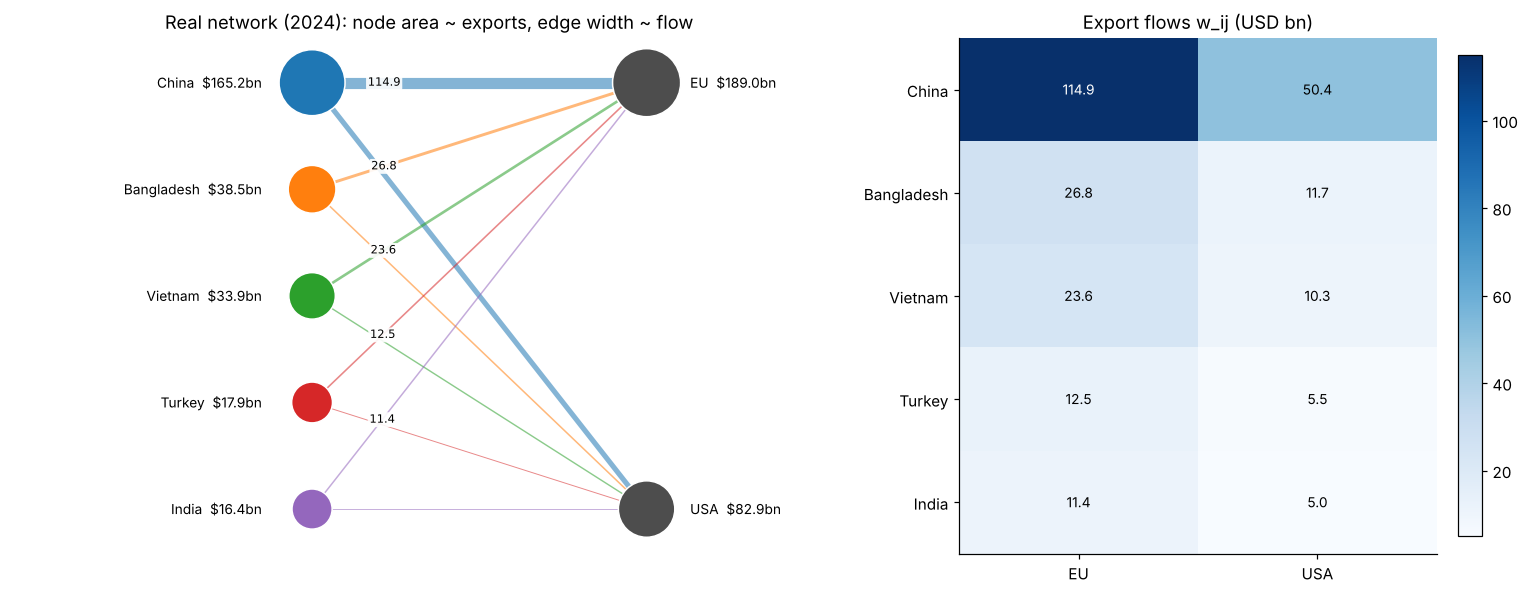

In [4]:
def draw_network(G, world, title, ax, ref=None, unit="$", fmt="{:.1f}bn"):
    """Producers left (biggest on top), markets right. Node area ~ size, edge width ~ flow.
    Each producer's biggest flow gets one label near the producer (labels never stack).
    ref = network before a shock: producers that lost output get a dashed ring."""
    prods, conss = world["producers"], world["consumers"]
    tot = sum(G.nodes[n]["size"] for n in prods)
    pos = {n: (0, -k) for k, n in enumerate(prods)}
    span = max(len(prods) - 1, 1)
    pos.update({n: (1, -k * span / max(len(conss) - 1, 1)) for k, n in enumerate(conss)})

    wmax = max(d["weight"] for _, _, d in G.edges(data=True))
    for u, v, d in G.edges(data=True):
        nx.draw_networkx_edges(G, pos, edgelist=[(u, v)], ax=ax, width=0.3 + 7 * d["weight"] / wmax,
                               edge_color=[world["colors"][u]], alpha=0.55, arrows=False)
    size = lambda x: 150 + 2200 * np.sqrt(x / tot)    # sqrt: the hub does not hide the rest
    nx.draw_networkx_nodes(G, pos, nodelist=prods, ax=ax, edgecolors="white",
                           node_size=[size(G.nodes[n]["size"]) for n in prods],
                           node_color=[world["colors"][n] for n in prods])
    nx.draw_networkx_nodes(G, pos, nodelist=conss, ax=ax, node_color=CONS_COLOR, edgecolors="white",
                           node_size=[size(G.nodes[n]["size"]) for n in conss])
    if ref is not None:
        hit = [n for n in prods if G.nodes[n]["size"] < ref.nodes[n]["size"] - 1e-9]
        nx.draw_networkx_nodes(G, pos, nodelist=hit, ax=ax, node_color="none", node_size=2500,
                               edgecolors="black", linewidths=1.2).set_linestyle("--")
    lab = lambda n: f"{world['labels'][n]}  {unit}" + fmt.format(G.nodes[n]["size"])
    for n in prods: ax.text(pos[n][0] - 0.15, pos[n][1], lab(n), ha="right", va="center", fontsize=9)
    for n in conss: ax.text(pos[n][0] + 0.13, pos[n][1], lab(n), ha="left", va="center", fontsize=9)
    top = [max(G.out_edges(n, data=True), key=lambda e: e[2]["weight"]) for n in prods]
    nx.draw_networkx_edge_labels(G, pos, ax=ax, label_pos=0.2, font_size=7.5, rotate=False,
        edge_labels={(u, v): fmt.format(d["weight"]).replace("bn", "") for u, v, d in top},
        bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.9))
    ax.set_xlim(-0.9, 1.6); ax.set_title(title); ax.axis("off")

def draw_heatmap(G, world, ax, title="Export flows w_ij", fmt="{:.1f}"):
    W = np.array([[G[i][j]["weight"] for j in world["consumers"]] for i in world["producers"]])
    im = ax.imshow(W, cmap="Blues", aspect="auto")
    ax.set_xticks(range(len(world["consumers"])), [world["labels"][j] for j in world["consumers"]])
    ax.set_yticks(range(len(world["producers"])), [world["labels"][i] for i in world["producers"]])
    for r in range(W.shape[0]):
        for c in range(W.shape[1]):
            ax.text(c, r, fmt.format(W[r, c]), ha="center", va="center", fontsize=9,
                    color="white" if W[r, c] > W.max() / 2 else "black")
    ax.grid(False); ax.set_title(title); plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

fig, ax = plt.subplots(1, 2, figsize=(14, 5.5), gridspec_kw={"width_ratios": [1.6, 1]})
draw_network(G_real, REAL, "Real network (2024): node area ~ exports, edge width ~ flow", ax[0])
draw_heatmap(G_real, REAL, ax[1], title="Export flows w_ij (USD bn)")
plt.tight_layout(); plt.show()

China is by far the biggest hub: its flow to the EU alone ($115bn) is three times Bangladesh's total exports.

In [5]:
# Hub measures on the real network. Eigenvector centrality on the undirected version:
# the directed network has no loops, so its largest eigenvalue would be 0 (Week 4).
strength = dict(G_real.out_degree(weight="weight"))
eig = nx.eigenvector_centrality_numpy(G_real.to_undirected(), weight="weight")
M = pd.DataFrame({"country": [REAL["labels"][i] for i in REAL["producers"]],
                  "strength_usd_bn": [strength[i] for i in REAL["producers"]],
                  "share": REAL["P"] / REAL["P"].sum(),
                  "eigenvector": [eig[i] for i in REAL["producers"]]}, index=REAL["producers"])
display(M.round(3))

,country,strength_usd_bn,share,eigenvector
CHN,China,165.24,0.608,0.669
BGD,Bangladesh,38.48,0.142,0.156
VNM,Vietnam,33.94,0.125,0.137
TUR,Turkey,17.91,0.066,0.072
IND,India,16.36,0.060,0.066


---
# 3. How unequal are the producers? The hub strength $\alpha$

Sorted by size, the real shares follow a power law in the rank:

$$s_r \propto r^{-\alpha}, \qquad r = 1, 2, \dots, 5$$

$\alpha = 0$ means all producers are equal (no hub, like the road network in Week 2); a larger $\alpha$ means one producer dominates (like the flight network). We fit $\alpha$ on a log-log plot.

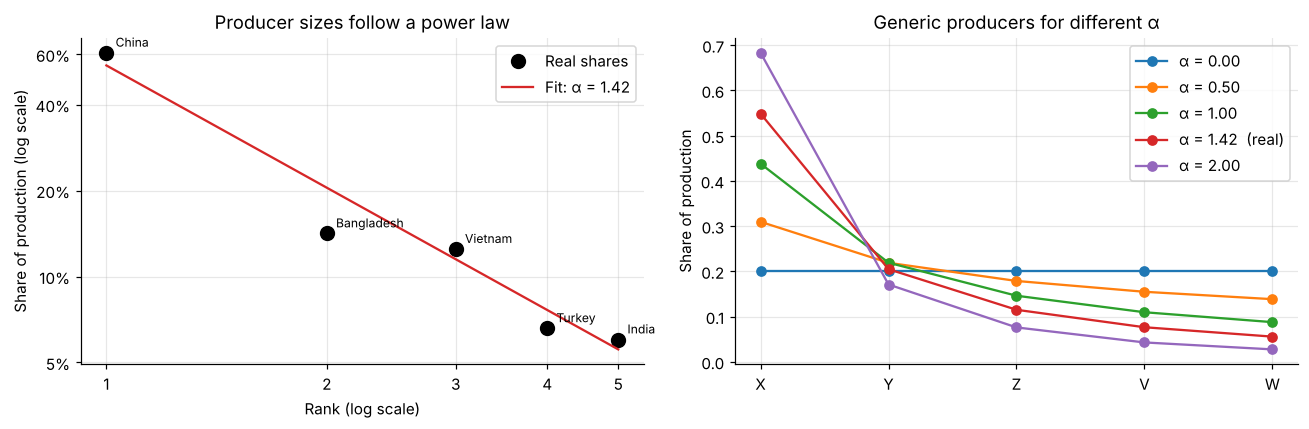

Fitted hub strength alpha = 1.42;  shares at this alpha: [0.549 0.205 0.115 0.076 0.056]


In [6]:
share_real = REAL["P"] / REAL["P"].sum()
rank = np.arange(1, len(share_real) + 1)
slope, intercept = np.polyfit(np.log(rank), np.log(share_real), 1)
ALPHA_REAL = -slope                                       # fitted hub strength

def shares(alpha, n=5):
    """Normalized producer shares s_r ~ r^-alpha (they add up to 1)."""
    s = np.arange(1, n + 1, dtype=float) ** (-alpha)
    return s / s.sum()

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].loglog(rank, share_real, "o", ms=9, color="black", label="Real shares")
ax[0].loglog(rank, shares(ALPHA_REAL), "-", color="tab:red", label=f"Fit: α = {ALPHA_REAL:.2f}")
for r, n in zip(rank, REAL["producers"]):
    ax[0].annotate(REAL["labels"][n], (r, share_real[r - 1]), textcoords="offset points", xytext=(6, 4), fontsize=8)
ax[0].set_xticks(rank, [str(r) for r in rank]); ax[0].minorticks_off()
ax[0].set_yticks([0.05, 0.1, 0.2, 0.4, 0.6], ["5%", "10%", "20%", "40%", "60%"])
ax[0].set_xlabel("Rank (log scale)"); ax[0].set_ylabel("Share of production (log scale)")
ax[0].set_title("Producer sizes follow a power law"); ax[0].legend()

for a in [0, 0.5, 1.0, ALPHA_REAL, 2.0]:
    ax[1].plot(rank, shares(a), "o-", label=f"α = {a:.2f}" + ("  (real)" if a == ALPHA_REAL else ""))
ax[1].set_xticks(rank, ["X", "Y", "Z", "V", "W"]); ax[1].set_ylabel("Share of production")
ax[1].set_title("Generic producers for different α"); ax[1].legend()
plt.tight_layout(); plt.show()
print(f"Fitted hub strength alpha = {ALPHA_REAL:.2f};  shares at this alpha: {np.round(shares(ALPHA_REAL), 3)}")

The real shares sit close to a straight line on the log-log plot, so one number describes how concentrated production is.

**From here on we use generic countries.** Producers X, Y, Z, V, W (X = biggest) have shares $s_r \propto r^{-\alpha}$ that add up to 1, and markets A and B take 70% and 30% of the demand (like the EU and USA). All producers get the **same wage**, so the only difference between them is size. That way every result comes from the network structure, not from country details.

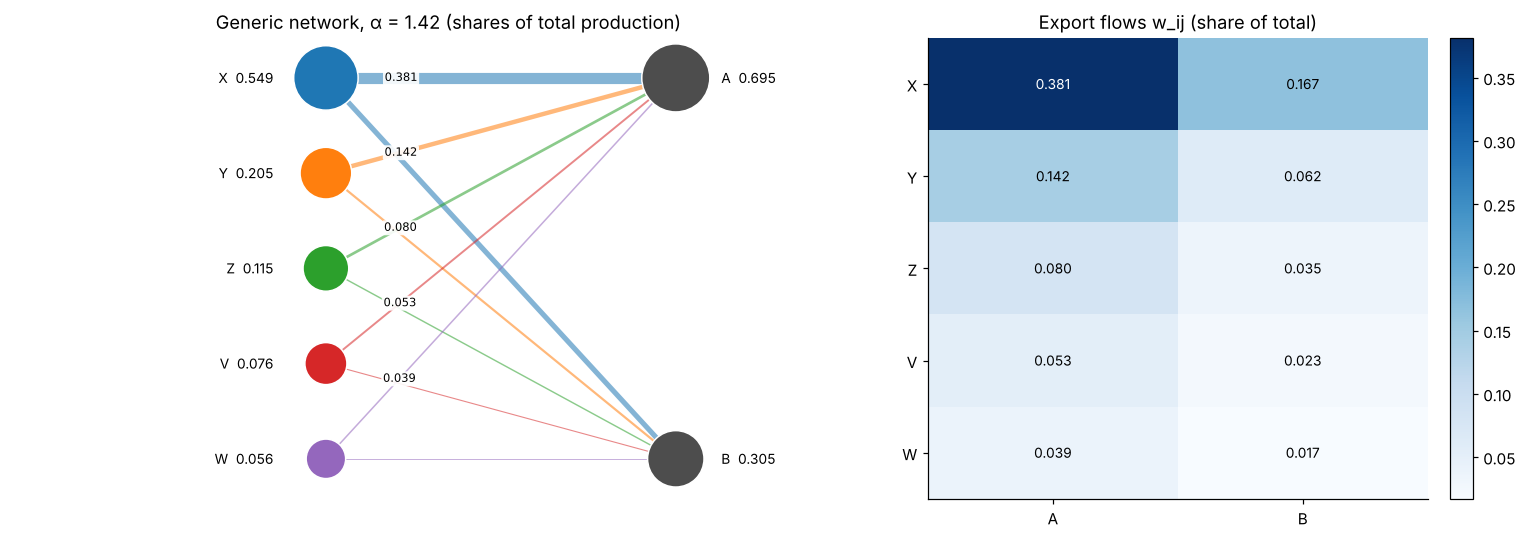

In [7]:
GEN_PRODUCERS = ["X", "Y", "Z", "V", "W"]
GEN_MARKETS = ["A", "B"]
MARKET_SHARES = cons.share.values                 # A ~ EU (70%), B ~ USA (30%)

def generic_world(alpha):
    return make_world(GEN_PRODUCERS, shares(alpha), GEN_MARKETS, MARKET_SHARES)

GEN = generic_world(ALPHA_REAL)                    # the baseline for the simulations
G_gen = build_network(GEN)
fig, ax = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [1.6, 1]})
draw_network(G_gen, GEN, f"Generic network, α = {ALPHA_REAL:.2f} (shares of total production)", ax[0], unit="", fmt="{:.3f}")
draw_heatmap(G_gen, GEN, ax[1], title="Export flows w_ij (share of total)", fmt="{:.3f}")
plt.tight_layout(); plt.show()

---
# 4. The market (macro perspective)

- **Supply:** $S_i(p) = \min(K_i,\; s_i\,(p - c_i))$: more output when the price is higher, up to capacity $K_i$.
- **Demand:** $D_j(p) = A_j - B_j\,p$: markets buy less when the price is higher.
- **Equilibrium:** one world price $p^*$ where $\sum_i S_i(p^*) = \sum_j D_j(p^*)$.

All market settings are in one dictionary, so a sweep only changes the dictionary.

Baseline: p* = 1.000, Q* = 1.000  (should be 1 and 1: shares add up to 1)


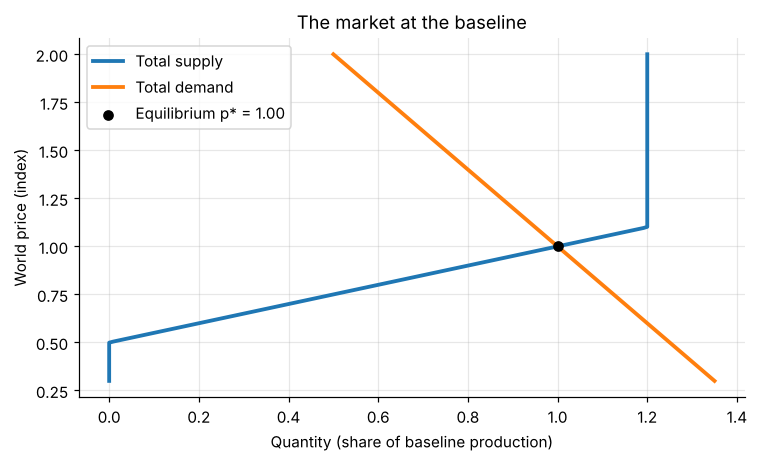

In [8]:
# MARKET PARAMETERS (README section 6, items 7-10). Change values here only.
PARAMS = dict(p0=1.0,        # baseline world price (normalized)
              lam=0.5,       # labour share: unit cost c_i = lam * W_i / W_max
              eps=0.5,       # demand price elasticity: B_j = eps * C_j / p0
              spare=0.2)     # spare capacity: K_i = P_i * (1 + spare)

def calibrate(world, par=PARAMS):
    """Numpy arrays so the market clears at p0 with the world's sizes."""
    P, W, C = world["P"], world["W"], world["C"]
    c = par["lam"] * W / W.max()                  # unit cost, always below p0
    s = P / (par["p0"] - c)                       # supply slope: S_i(p0) = P_i
    K = P * (1 + par["spare"])                    # capacity
    B = par["eps"] * C / par["p0"]                # demand slope
    A = C + B * par["p0"]                         # demand intercept: D_j(p0) = C_j
    return dict(P=P, c=c, s=s, K=K, A=A, B=B, p0=par["p0"])

def supply(p, m, K=None):
    """Supply of every producer at price p (vectorized; K can be overridden by a shock)."""
    K = m["K"] if K is None else K
    return np.minimum(K, np.maximum(0.0, m["s"] * (p - m["c"])))

def demand(p, m):
    return np.maximum(0.0, m["A"] - m["B"] * p)

def equilibrium(m, K=None):
    """World price where total supply = total demand."""
    excess = lambda p: demand(p, m).sum() - supply(p, m, K).sum()
    p = brentq(excess, 1e-6, 50 * m["p0"])
    return p, supply(p, m, K), demand(p, m)

MKT = calibrate(GEN)
p_star, S_star, D_star = equilibrium(MKT)
print(f"Baseline: p* = {p_star:.3f}, Q* = {S_star.sum():.3f}  (should be 1 and 1: shares add up to 1)")

p_grid = np.linspace(0.3, 2.0, 300)
fig, ax = plt.subplots(figsize=(7, 4.3))
ax.plot([supply(p, MKT).sum() for p in p_grid], p_grid, lw=2.5, label="Total supply")
ax.plot([demand(p, MKT).sum() for p in p_grid], p_grid, lw=2.5, label="Total demand")
ax.scatter([S_star.sum()], [p_star], color="black", zorder=5, label=f"Equilibrium p* = {p_star:.2f}")
ax.set_xlabel("Quantity (share of baseline production)"); ax.set_ylabel("World price (index)")
ax.set_title("The market at the baseline"); ax.legend(); plt.tight_layout(); plt.show()

The supply curve turns vertical at 1.2: total capacity is 20% above today's production. A shock that removes capacity moves this vertical part to the left, so the price rises until demand falls to what is left.

---
# 5. Simulation 1: removing the biggest hub (failure vs. attack)

- **Targeted attack:** remove a share $f$ of the biggest producer's (X) factories, so its capacity becomes $K_X = (1-f)\,P_X$.
- **Random failure (control):** one producer, picked at random, loses the same share $f$. Every producer is equally likely, so we run all 5 and average them (the exact expected value).
- After every shock we solve the new equilibrium; the other producers take over part of the output through the price.

In [9]:
F = np.linspace(0, 1, 21)                          # f = 0, 0.05, ..., 1

def shock(m, k, f):
    """Capacity vector after removing a share f of producer k's factories."""
    K = m["K"].copy()
    K[k] = min(K[k], (1 - f) * m["P"][k])
    return K

def run_attack(m, k, f):
    p, S, D = equilibrium(m, shock(m, k, f))
    return dict(f=f, k=k, price=p, Q=S.sum() / m["P"].sum(), S=S, D=D)

def attack_vs_random(world, par=PARAMS):
    """Targeted attack on the biggest producer vs. the average over all producers."""
    m = calibrate(world, par)
    att = pd.DataFrame([run_attack(m, 0, f) for f in F])
    rnd = pd.DataFrame([run_attack(m, k, f) for k in range(len(world["P"])) for f in F])
    return att, rnd.groupby("f")[["price", "Q"]].agg(["mean", "min", "max"])

attack, rand_stats = attack_vs_random(GEN)
display(attack[["f", "price", "Q"]].iloc[::4].round(3))

,f,price,Q
0,0.0,1.000,1.000
4,0.2,1.078,0.961
8,0.4,1.258,0.871
12,0.6,1.478,0.761
16,0.8,1.697,0.651
20,1.0,1.917,0.542


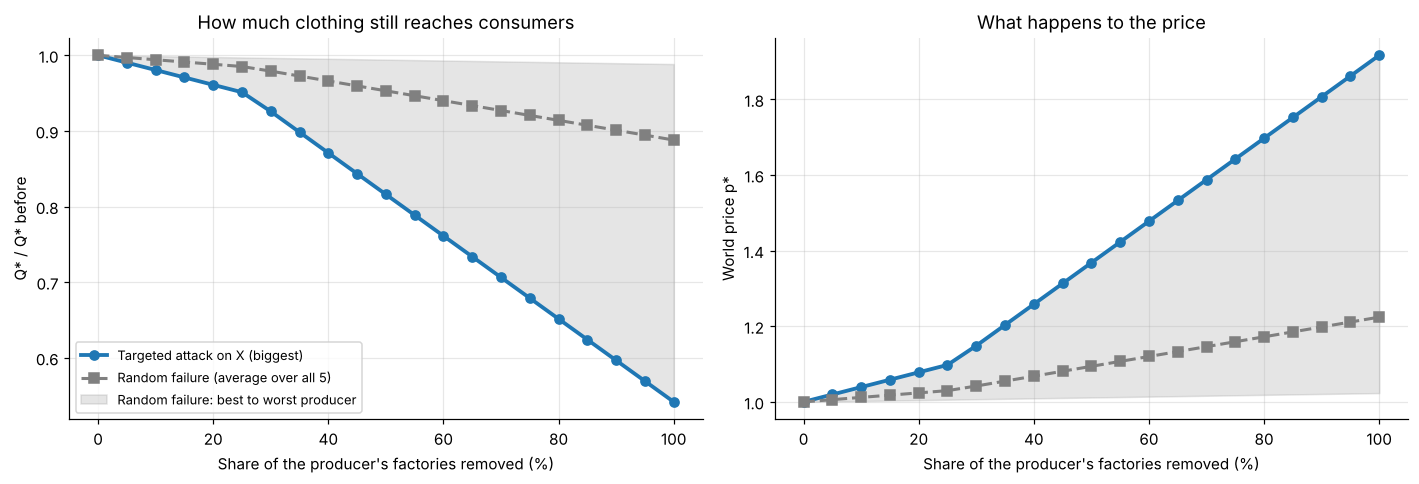

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for a, col, ylab, ttl in [(ax[0], "Q", "Q* / Q* before", "How much clothing still reaches consumers"),
                          (ax[1], "price", "World price p*", "What happens to the price")]:
    a.plot(F * 100, attack[col], "o-", color=GEN["colors"]["X"], lw=2.5, label="Targeted attack on X (biggest)")
    a.plot(F * 100, rand_stats[(col, "mean")], "s--", color="gray", lw=2, label="Random failure (average over all 5)")
    a.fill_between(F * 100, rand_stats[(col, "min")], rand_stats[(col, "max")], color="gray", alpha=0.2,
                   label="Random failure: best to worst producer")
    a.set_xlabel("Share of the producer's factories removed (%)"); a.set_ylabel(ylab); a.set_title(ttl)
ax[0].legend(fontsize=8.5, loc="lower left")
plt.tight_layout(); plt.show()

Attacking the hub costs much more than a random failure of the same size. Removing 20% of X's factories already raises the price by about 8% and cuts trade by about 4%; removing all of them cuts trade by almost half (−46%) and nearly doubles the price. A random failure usually hits a small producer, so the others cover it and the price hardly moves; the top of the grey band is the case where the random pick is X. This is the class result: robust to random failure, fragile when the hub is attacked.

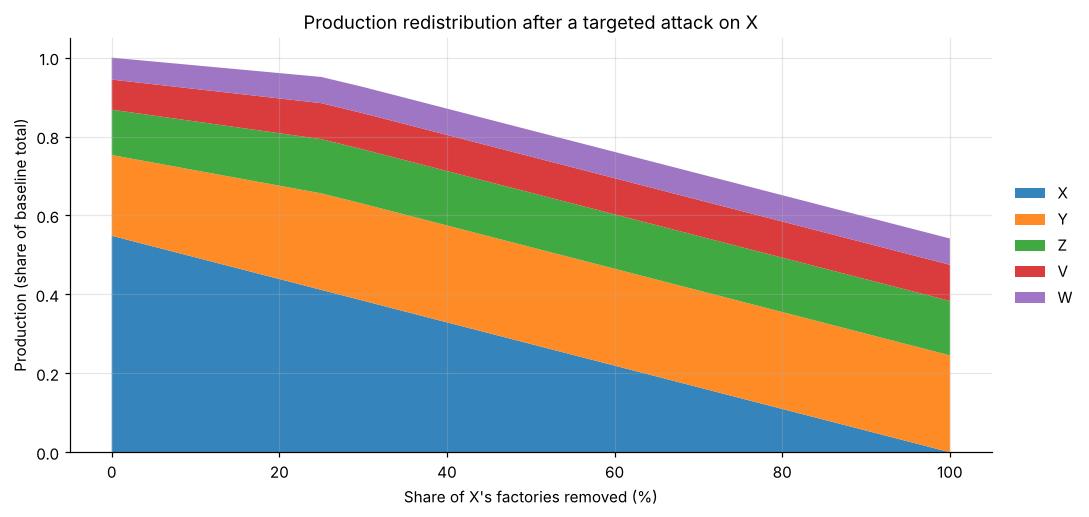

Output change of the other producers when X loses 50% (%):
Y    20.0
Z    20.0
V    20.0
W    20.0


In [11]:
# Who takes over the production? Output of every producer under the targeted attack
S_mat = np.vstack(attack.S.values)
fig, ax = plt.subplots(figsize=(10, 4.8))
ax.stackplot(F * 100, S_mat.T, colors=[GEN["colors"][n] for n in GEN["producers"]], labels=GEN["producers"], alpha=0.9)
ax.set_xlabel("Share of X's factories removed (%)"); ax.set_ylabel("Production (share of baseline total)")
ax.set_title("Production redistribution after a targeted attack on X")
ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5), frameon=False)
plt.tight_layout(); plt.show()

row = attack.loc[np.isclose(attack.f, 0.5)].iloc[0]
print("Output change of the other producers when X loses 50% (%):")
print(pd.Series(100 * (row.S[1:] / GEN["P"][1:] - 1), index=GEN["producers"][1:]).round(1).to_string())

The other producers grow until they hit their capacity limit (+20%). After that, every extra unit X loses is lost trade, which is why the curve keeps falling.

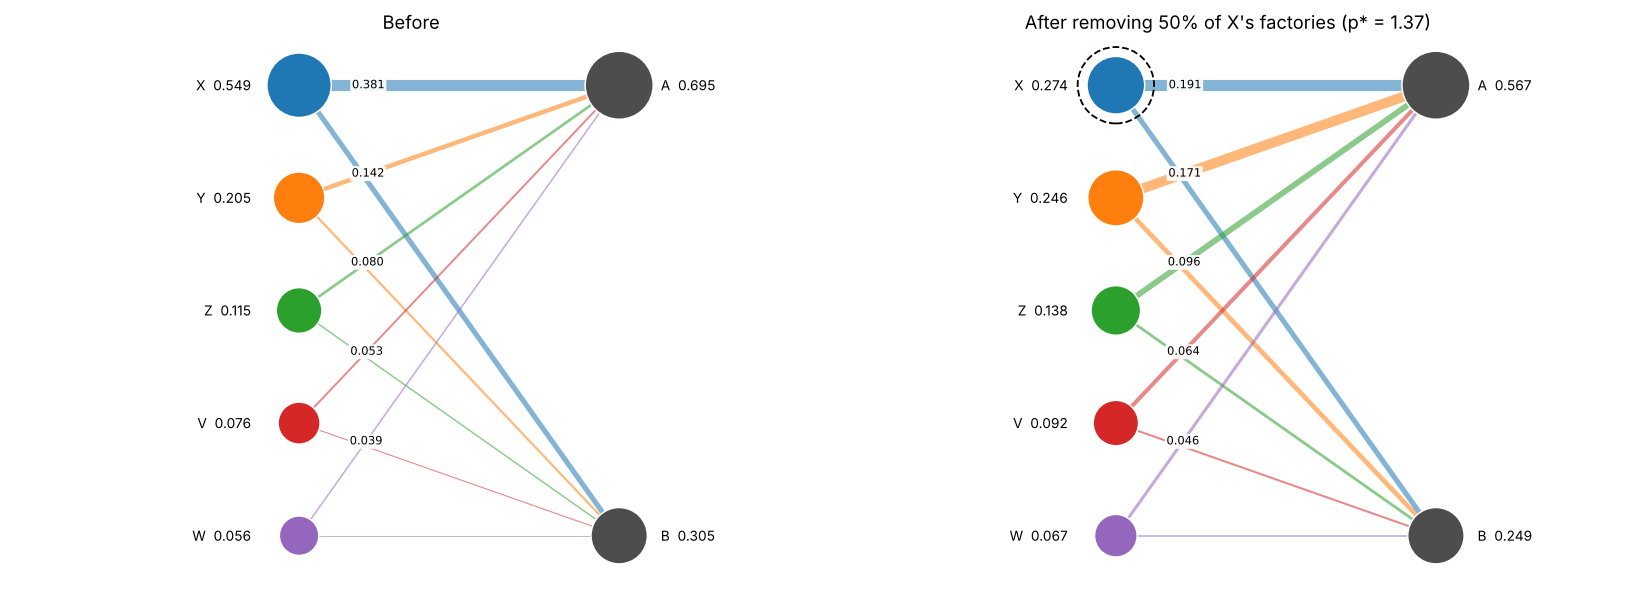

In [12]:
# The network after a 50% attack on X, next to the baseline
p, S, D = equilibrium(MKT, shock(MKT, 0, 0.5))
G_hit = build_network(GEN, P=S, C=D)
fig, ax = plt.subplots(1, 2, figsize=(15, 5.5))
draw_network(G_gen, GEN, "Before", ax[0], unit="", fmt="{:.3f}")
draw_network(G_hit, GEN, f"After removing 50% of X's factories (p* = {p:.2f})", ax[1], ref=G_gen, unit="", fmt="{:.3f}")
plt.tight_layout(); plt.show()

---
# 6. Hub strength: does concentration make the network fragile?

Now we change $\alpha$ and rerun Simulation 1 each time. $\alpha = 0$ (all producers equal) is the control: with no hub, attacking "the biggest" producer is the same as a random failure.

,alpha,share_X,attack_Q,random_Q,attack_p,random_p
0,0.00,0.200,0.976,0.976,1.048,1.048
1,0.25,0.251,0.969,0.976,1.063,1.048
2,0.50,0.309,0.959,0.976,1.082,1.049
3,0.75,0.372,0.939,0.973,1.121,1.053
4,1.00,0.438,0.893,0.966,1.213,1.068
5,1.25,0.504,0.847,0.958,1.306,1.084
6,1.50,0.568,0.802,0.951,1.395,1.099
7,1.75,0.628,0.760,0.944,1.480,1.113
8,2.00,0.683,0.722,0.937,1.557,1.125
9,2.25,0.732,0.687,0.932,1.625,1.137


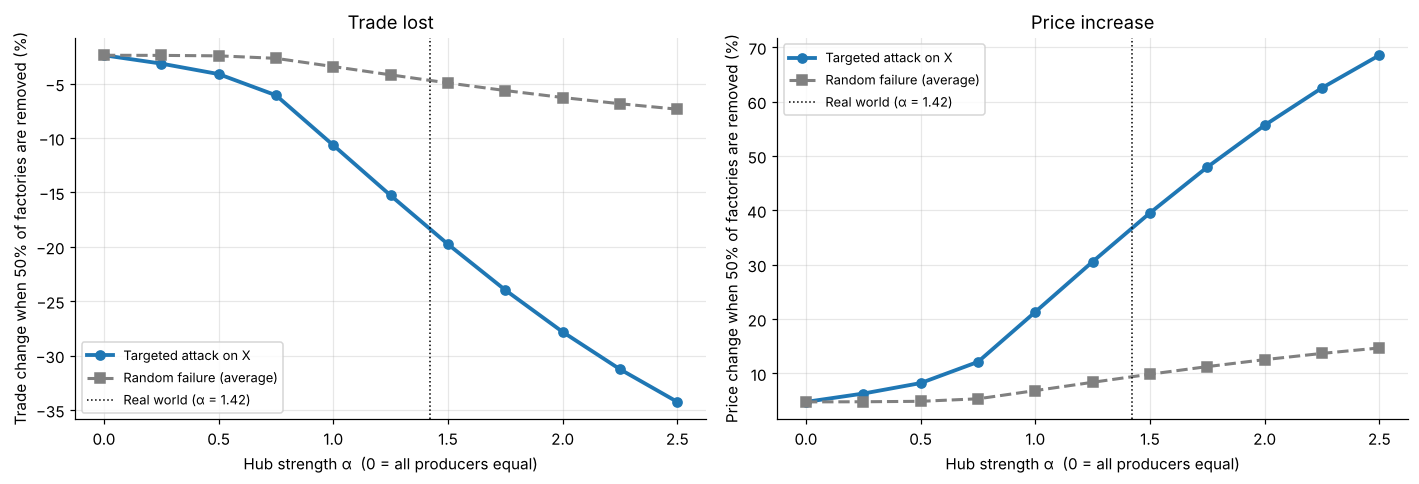

In [13]:
ALPHAS = np.round(np.linspace(0, 2.5, 11), 2)
F_TEST = 0.5                                               # remove half of the factories
k_test = int(np.argmin(np.abs(F - F_TEST)))

rows = []
for a in ALPHAS:
    att, rs = attack_vs_random(generic_world(a))
    rows.append(dict(alpha=a, share_X=shares(a)[0],
                     attack_Q=att.Q.iloc[k_test], random_Q=rs[("Q", "mean")].iloc[k_test],
                     attack_p=att.price.iloc[k_test], random_p=rs[("price", "mean")].iloc[k_test]))
sweep = pd.DataFrame(rows)
display(sweep.round(3))

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].plot(sweep.alpha, 100 * (sweep.attack_Q - 1), "o-", lw=2.5, color=PALETTE[0], label="Targeted attack on X")
ax[0].plot(sweep.alpha, 100 * (sweep.random_Q - 1), "s--", lw=2, color="gray", label="Random failure (average)")
ax[0].set_ylabel(f"Trade change when {int(F_TEST*100)}% of factories are removed (%)")
ax[1].plot(sweep.alpha, 100 * (sweep.attack_p - 1), "o-", lw=2.5, color=PALETTE[0], label="Targeted attack on X")
ax[1].plot(sweep.alpha, 100 * (sweep.random_p - 1), "s--", lw=2, color="gray", label="Random failure (average)")
ax[1].set_ylabel(f"Price change when {int(F_TEST*100)}% of factories are removed (%)")
for a in ax:
    a.axvline(ALPHA_REAL, color="black", ls=":", lw=1, label=f"Real world (α = {ALPHA_REAL:.2f})")
    a.set_xlabel("Hub strength α  (0 = all producers equal)"); a.legend(fontsize=8.5)
ax[0].set_title("Trade lost"); ax[1].set_title("Price increase")
plt.tight_layout(); plt.show()

With equal producers ($\alpha = 0$) the attack and the random failure give the same result: there is no hub to attack. As $\alpha$ grows, the gap opens: the attack gets much worse while random failure stays mild. The real world sits well inside the fragile range. So the reason a Bangladesh-sized shock is small is the same reason a China-sized shock is large: production is concentrated in one hub.

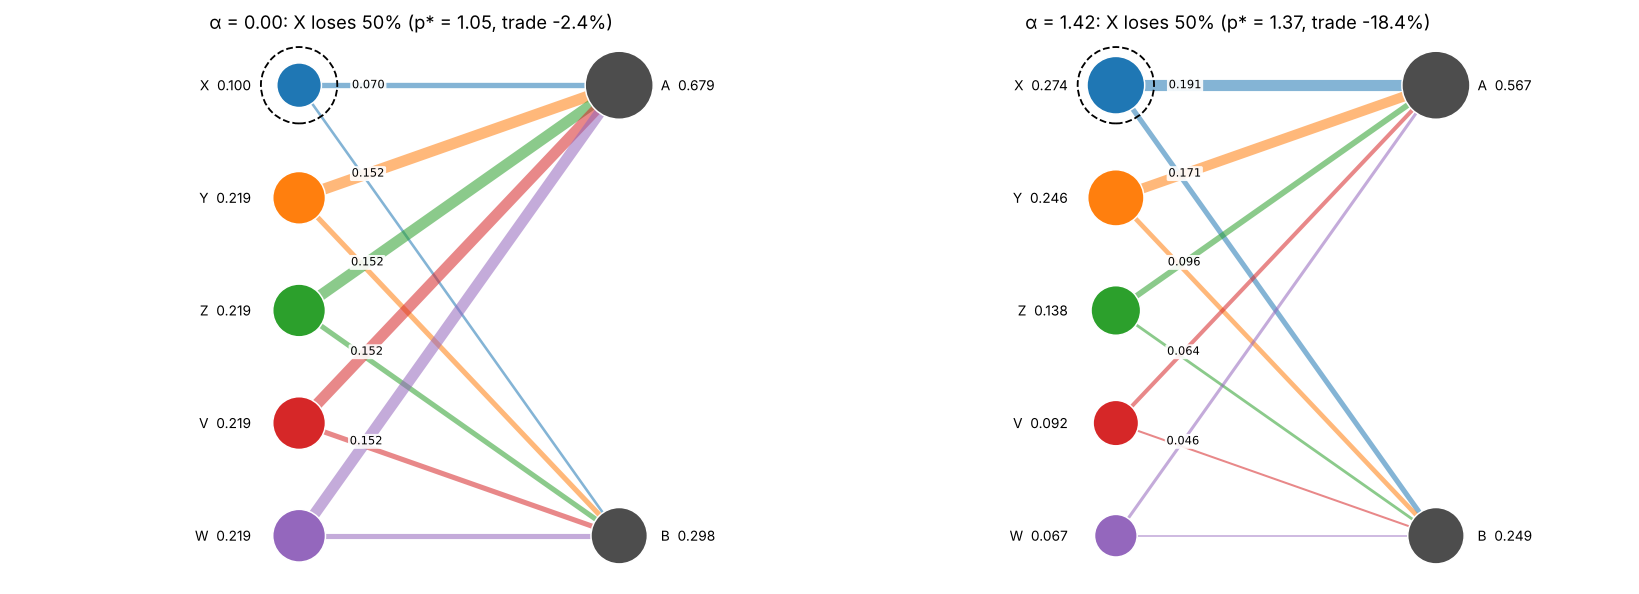

In [14]:
# The two extremes side by side: no hub vs the real hub strength, both after a 50% attack on X
fig, ax = plt.subplots(1, 2, figsize=(15, 5.5))
for a_, alpha in zip(ax, [0.0, ALPHA_REAL]):
    w = generic_world(alpha); m = calibrate(w)
    p, S, D = equilibrium(m, shock(m, 0, 0.5))
    draw_network(build_network(w, P=S, C=D), w, f"α = {alpha:.2f}: X loses 50% (p* = {p:.2f}, trade {100*(S.sum()-1):.1f}%)",
                 a_, ref=build_network(w), unit="", fmt="{:.3f}")
plt.tight_layout(); plt.show()

---
# 7. Sensitivity: how much do the chosen parameters matter?

Demand elasticity $\varepsilon$ and the spare capacity share have no data behind them, so we sweep them at the real hub strength.

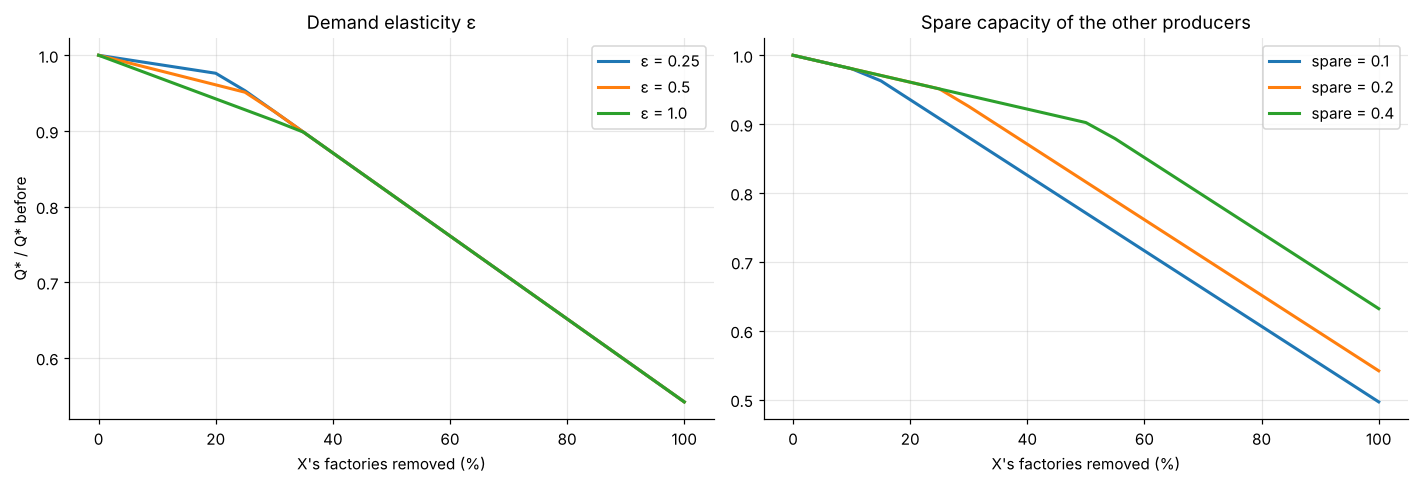

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for eps in [0.25, 0.5, 1.0]:
    att, _ = attack_vs_random(GEN, dict(PARAMS, eps=eps))
    ax[0].plot(F * 100, att.Q, lw=2, label=f"ε = {eps}")
ax[0].set_title("Demand elasticity ε"); ax[0].set_ylabel("Q* / Q* before")
for spare in [0.1, 0.2, 0.4]:
    att, _ = attack_vs_random(GEN, dict(PARAMS, spare=spare))
    ax[1].plot(F * 100, att.Q, lw=2, label=f"spare = {spare}")
ax[1].set_title("Spare capacity of the other producers")
for a in ax: a.set_xlabel("X's factories removed (%)"); a.legend()
plt.tight_layout(); plt.show()

More spare capacity means the other producers can replace more of X's lost output, so less trade is lost. Demand elasticity only matters for small shocks; for large ones every other producer is at full capacity and trade is limited by what is left. The main result (attacking the hub is much worse than a random failure) holds for every value we tried.

---
# 8. Next steps

- Simulation 2 (brand ethics): Brand B only uses producers with safety score $S_i \ge T$, so it gets its own equilibrium price.
- Simulation 3 (wages): new factories by preferential attachment; wages raise $c_i$.
- Simulation 4 (pollution haven): stricter rules raise $c_i = \lambda W_i (1 + \kappa E_i/10)$.

**AI Prompts Used Throughout the Whole Assignment**

1. (add the prompts you used here, as in the Vilar notebook)